In [16]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO
import random
import shutil

import json

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 5.2 MB/s eta 0:00:00


In [4]:
# Locate the CrackVision Model
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
WEIGHTS_PATH = DRIVE_ROOT / "models" / "crackvision-yolo11n-seg-best.pt"

print("Project folder exists:", DRIVE_ROOT.exists())
print("Model weights exist:", WEIGHTS_PATH.exists())

if WEIGHTS_PATH.exists():
    print(f"Model file size: {WEIGHTS_PATH.stat().st_size / (1024 * 1024):.2f} MB")
else:
    print("Model not found. Available model files:")
    models_dir = DRIVE_ROOT / "models"

    if models_dir.exists():
        for path in models_dir.glob("*.pt"):
            print(path.name)

Project folder exists: True
Model weights exist: True
Model file size: 5.75 MB


In [5]:
# Load the trained segmentation model
# Load our previously trained CrackVision model
model = YOLO(str(WEIGHTS_PATH))

print("CrackVision model loaded successfully!")
print("Model file:", WEIGHTS_PATH.name)
print("Task:", model.task)
print("Classes:", model.names)
print("Number of classes:", len(model.names))

CrackVision model loaded successfully!
Model file: crackvision-yolo11n-seg-best.pt
Task: segment
Classes: {0: 'crack'}
Number of classes: 1


In [11]:
# Restore the Dataset from google Drive
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackVision")
DRIVE_DATASET_DIR = DRIVE_ROOT / "data" / "crack-seg"
DATASET_DIR = Path("/content/crack-seg")

# Verify the persistent dataset exists before copying
if not (DRIVE_DATASET_DIR / "crack-seg.yaml").exists():
    raise FileNotFoundError(
        f"Dataset configuration not found at {DRIVE_DATASET_DIR}. "
        "We'll need to locate its actual Drive folder."
    )

# Restore the dataset to Colab's temporary workspace
if not DATASET_DIR.exists():
    shutil.copytree(DRIVE_DATASET_DIR, DATASET_DIR)

TEST_IMAGES_DIR = DATASET_DIR / "images" / "test"

test_images = sorted(
    path for path in TEST_IMAGES_DIR.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
) if TEST_IMAGES_DIR.exists() else []

print("Dataset restored:", DATASET_DIR.exists())
print("Test images found:", len(test_images))

if not test_images:
    raise FileNotFoundError(
        f"No test images found in {TEST_IMAGES_DIR}"
    )

Dataset restored: True
Test images found: 112


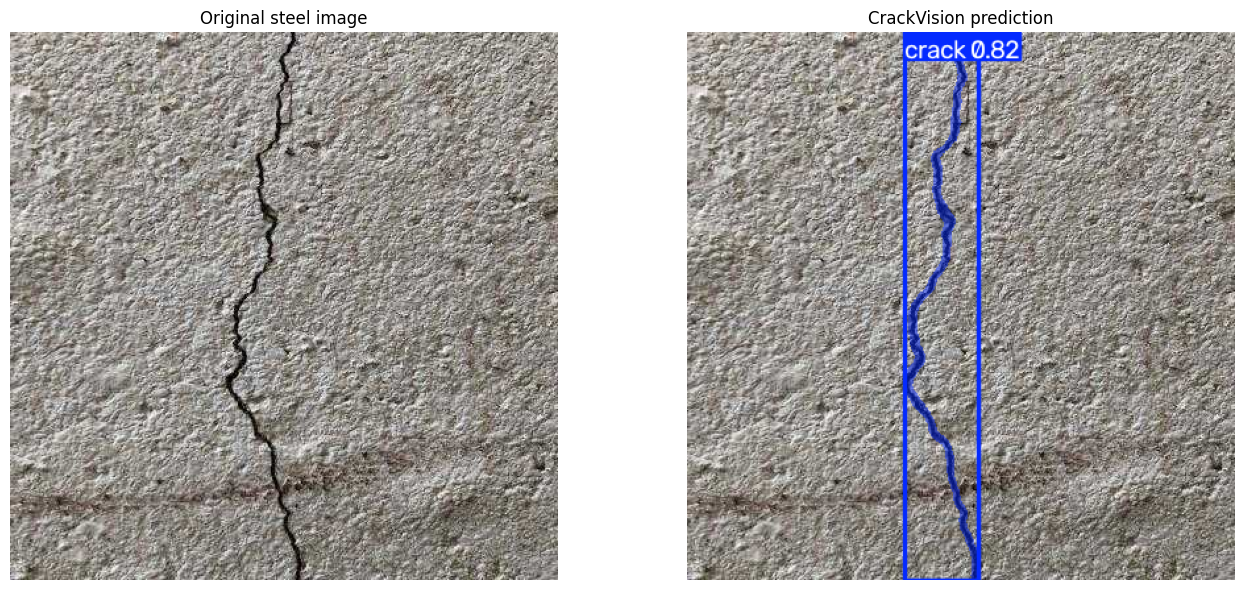

Image: 3225.rf.00490d0babc76539398c471f17b0d6e7.jpg
Detections: 1
Detection 1: crack, confidence=0.821


In [12]:
# Run inference
# Select a reproducible test image
rng = random.Random(42)
image_path = rng.choice(test_images)

# Run segmentation inference
result = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    save=False,
    verbose=False
)[0]

# Convert the annotated image from BGR to RGB for Matplotlib
annotated_bgr = result.plot()
annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

# Display original and predicted result
original_bgr = cv2.imread(str(image_path))
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(original_rgb)
axes[0].set_title("Original steel image")
axes[0].axis("off")

axes[1].imshow(annotated_rgb)
axes[1].set_title("CrackVision prediction")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_path.name)
print("Detections:", len(result.boxes))

if result.boxes is not None:
    for i, box in enumerate(result.boxes):
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        print(
            f"Detection {i + 1}: "
            f"{model.names[class_id]}, confidence={confidence:.3f}"
        )

In [15]:
# Save the prediction result
# Persistent output directory in Google Drive
INFERENCE_DIR = (
    Path("/content/drive/MyDrive/CrackVision")
    / "inference-results"
)
INFERENCE_DIR.mkdir(parents=True, exist_ok=True)

# Save the annotated image
annotated_path = INFERENCE_DIR / f"{image_path.stem}_prediction.jpg"

if not cv2.imwrite(str(annotated_path), annotated_bgr):
    raise IOError(f"Failed to save image: {annotated_path}")

# Record detections in a CSV file
detection_records = []

if result.boxes is not None:
    for box in result.boxes:
        class_id = int(box.cls.item())
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().tolist()

        detection_records.append({
            "image": image_path.name,
            "class": model.names[class_id],
            "confidence": float(box.conf.item()),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,
        })

csv_path = INFERENCE_DIR / "detections.csv"
new_records = pd.DataFrame(detection_records)

if csv_path.exists():
    existing_records = pd.read_csv(csv_path)
    new_records = pd.concat(
        [existing_records, new_records],
        ignore_index=True
    )

new_records.to_csv(csv_path, index=False)

print("Annotated image saved:", annotated_path)
print("Detection records saved:", csv_path)
print("Detections recorded:", len(detection_records))

Annotated image saved: /content/drive/MyDrive/CrackVision/inference-results/3225.rf.00490d0babc76539398c471f17b0d6e7_prediction.jpg
Detection records saved: /content/drive/MyDrive/CrackVision/inference-results/detections.csv
Detections recorded: 1


In [17]:
# Extract segmentation polygons
# Store polygon data separately from the detection CSV
polygon_records = []

if result.masks is not None:
    for i, polygon in enumerate(result.masks.xy):
        class_id = int(result.boxes.cls[i].item())
        confidence = float(result.boxes.conf[i].item())

        # Each point is an (x, y) pixel coordinate
        points = np.asarray(polygon, dtype=np.float32)

        polygon_records.append({
            "image": image_path.name,
            "class": model.names[class_id],
            "confidence": confidence,
            "num_points": len(points),
            "polygon_xy": points.tolist(),
        })

polygon_path = INFERENCE_DIR / f"{image_path.stem}_polygons.json"

with polygon_path.open("w") as file:
    json.dump(polygon_records, file, indent=2)

print("Image:", image_path.name)
print("Detected segmentation masks:", len(polygon_records))
print("Polygon data saved:", polygon_path)

for i, record in enumerate(polygon_records, start=1):
    print(
        f"Mask {i}: {record['num_points']} polygon points, "
        f"confidence={record['confidence']:.3f}"
    )

Image: 3225.rf.00490d0babc76539398c471f17b0d6e7.jpg
Detected segmentation masks: 1
Polygon data saved: /content/drive/MyDrive/CrackVision/inference-results/3225.rf.00490d0babc76539398c471f17b0d6e7_polygons.json
Mask 1: 605 polygon points, confidence=0.821


In [18]:
# Measure predicted crack region
measurement_records = []

for i, polygon in enumerate(result.masks.xy if result.masks is not None else []):
    points = np.asarray(polygon, dtype=np.float32)

    if len(points) < 3:
        continue

    contour = points.reshape(-1, 1, 2)

    # Bounding-box dimensions in pixels
    x, y, width, height = cv2.boundingRect(contour)

    # Area enclosed by the predicted polygon
    area_px2 = cv2.contourArea(contour)

    # Length of the polygon's closed boundary
    perimeter_px = cv2.arcLength(contour, closed=True)

    measurement_records.append({
        "image": image_path.name,
        "detection_id": i + 1,
        "class": model.names[int(result.boxes.cls[i].item())],
        "confidence": float(result.boxes.conf[i].item()),
        "width_px": width,
        "height_px": height,
        "area_px2": area_px2,
        "perimeter_px": perimeter_px,
        "aspect_ratio": width / height if height else np.nan,
    })

measurement_df = pd.DataFrame(measurement_records)

if not measurement_df.empty:
    display(measurement_df.round(2))
else:
    print("No valid segmentation polygons were detected.")

,image,detection_id,class,confidence,width_px,height_px,area_px2,perimeter_px,aspect_ratio
0,3225.rf.00490d0babc76539398c471f17b0d6e7.jpg,1,crack,0.82,57,416,2695.97,965.75,0.14


In [19]:
# save the measurements to Google Drive
measurement_csv = INFERENCE_DIR / "crack_measurements.csv"

if measurement_df.empty:
    print("No measurements to save.")
else:
    # Save this run's measurements
    measurement_df.to_csv(measurement_csv, index=False)

    print("Measurements saved successfully!")
    print("File:", measurement_csv)
    print("Rows:", len(measurement_df))
    print("Columns:", list(measurement_df.columns))

    display(measurement_df.round(2))

Measurements saved successfully!
File: /content/drive/MyDrive/CrackVision/inference-results/crack_measurements.csv
Rows: 1
Columns: ['image', 'detection_id', 'class', 'confidence', 'width_px', 'height_px', 'area_px2', 'perimeter_px', 'aspect_ratio']


,image,detection_id,class,confidence,width_px,height_px,area_px2,perimeter_px,aspect_ratio
0,3225.rf.00490d0babc76539398c471f17b0d6e7.jpg,1,crack,0.82,57,416,2695.97,965.75,0.14


In [20]:
# Create a reusable inference function
def inspect_steel_image(image_path, confidence=0.25, imgsz=640):
    """
    Run crack segmentation on one steel image.

    Returns:
        annotated_rgb: Image with predicted masks and labels.
        detections_df: Table of detections and pixel-based geometry.
    """
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")

    prediction = model.predict(
        source=str(image_path),
        imgsz=imgsz,
        conf=confidence,
        verbose=False
    )[0]

    annotated_rgb = cv2.cvtColor(
        prediction.plot(),
        cv2.COLOR_BGR2RGB
    )

    records = []

    if prediction.masks is not None:
        for i, polygon in enumerate(prediction.masks.xy):
            points = np.asarray(polygon, dtype=np.float32)

            if len(points) < 3:
                continue

            contour = points.reshape(-1, 1, 2)
            x, y, width, height = cv2.boundingRect(contour)

            class_id = int(prediction.boxes.cls[i].item())

            records.append({
                "image": image_path.name,
                "class": model.names[class_id],
                "confidence": float(prediction.boxes.conf[i].item()),
                "x": x,
                "y": y,
                "width_px": width,
                "height_px": height,
                "area_px2": cv2.contourArea(contour),
                "perimeter_px": cv2.arcLength(contour, True),
            })

    return annotated_rgb, pd.DataFrame(records)


print("Reusable inference function defined successfully!")

Reusable inference function defined successfully!


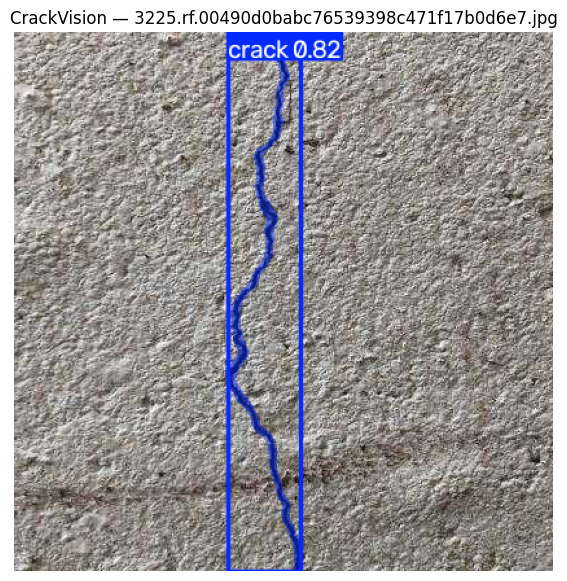

Detections found: 1


,image,class,confidence,x,y,width_px,height_px,area_px2,perimeter_px
0,3225.rf.00490d0babc76539398c471f17b0d6e7.jpg,crack,0.82,165,0,57,416,2695.97,965.75


In [21]:
# Test the inference function
# Run the reusable pipeline on our selected test image
annotated_rgb, detections_df = inspect_steel_image(
    image_path=image_path,
    confidence=0.25,
    imgsz=640
)

# Display the result
plt.figure(figsize=(10, 7))
plt.imshow(annotated_rgb)
plt.title(f"CrackVision — {Path(image_path).name}")
plt.axis("off")
plt.show()

# Display the structured output
print("Detections found:", len(detections_df))

if detections_df.empty:
    print("No cracks detected at the current confidence threshold.")
else:
    display(detections_df.round(2))

In [22]:
# Batch inference on multiple images
def inspect_image_folder(
    image_dir,
    confidence=0.25,
    imgsz=640,
    output_csv=None
):
    """Run CrackVision on every supported image in a folder."""

    image_dir = Path(image_dir)

    if not image_dir.is_dir():
        raise NotADirectoryError(f"Image folder not found: {image_dir}")

    extensions = {".jpg", ".jpeg", ".png", ".bmp"}
    image_paths = sorted(
        path for path in image_dir.iterdir()
        if path.is_file() and path.suffix.lower() in extensions
    )

    if not image_paths:
        raise ValueError(f"No supported images found in {image_dir}")

    all_detections = []

    for index, path in enumerate(image_paths, start=1):
        _, detections = inspect_steel_image(
            path,
            confidence=confidence,
            imgsz=imgsz
        )

        all_detections.extend(detections.to_dict("records"))

        print(
            f"[{index}/{len(image_paths)}] {path.name}: "
            f"{len(detections)} detection(s)"
        )

    results_df = pd.DataFrame(all_detections)

    if output_csv is not None:
        output_csv = Path(output_csv)
        output_csv.parent.mkdir(parents=True, exist_ok=True)
        results_df.to_csv(output_csv, index=False)
        print(f"\nResults saved to: {output_csv}")

    print(f"\nImages processed: {len(image_paths)}")
    print(f"Total detections: {len(results_df)}")

    return results_df


print("Batch inference function defined successfully!")

Batch inference function defined successfully!


In [23]:
# Run the batch inference on five images
TEST_IMAGES_DIR = Path("/content/crack-seg/images/test")
INFERENCE_DIR = (
    Path("/content/drive/MyDrive/CrackVision")
    / "inference-results"
)

# Select five images deterministically
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

test_image_paths = sorted(
    p for p in TEST_IMAGES_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
)

if not test_image_paths:
    raise FileNotFoundError(
        f"No test images found in {TEST_IMAGES_DIR}"
    )

sample_dir = INFERENCE_DIR / "batch-sample"
sample_dir.mkdir(parents=True, exist_ok=True)

sample_paths = test_image_paths[:5]

print("Images selected:")
for path in sample_paths:
    print("-", path.name)

sample_results = []

for index, path in enumerate(sample_paths, start=1):
    _, detections = inspect_steel_image(
        path,
        confidence=0.25,
        imgsz=640
    )

    sample_results.extend(detections.to_dict("records"))

    print(f"[{index}/{len(sample_paths)}] {len(detections)} detection(s)")

sample_df = pd.DataFrame(sample_results)
sample_csv = sample_dir / "batch_sample_results.csv"
sample_df.to_csv(sample_csv, index=False)

print("\nBatch test completed!")
print("Images processed:", len(sample_paths))
print("Total detections:", len(sample_df))
print("Results saved to:", sample_csv)

display(sample_df.round(2))

Images selected:
- 1616.rf.c868709931a671796794fdbb95352c5a.jpg
- 1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f.jpg
- 1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8.jpg
- 1706.rf.011d213c21ec78896c36728dcbc156f5.jpg
- 1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg
[1/5] 2 detection(s)
[2/5] 1 detection(s)
[3/5] 1 detection(s)
[4/5] 0 detection(s)
[5/5] 2 detection(s)

Batch test completed!
Images processed: 5
Total detections: 6
Results saved to: /content/drive/MyDrive/CrackVision/inference-results/batch-sample/batch_sample_results.csv


,image,class,confidence,x,y,width_px,height_px,area_px2,perimeter_px
0,1616.rf.c868709931a671796794fdbb95352c5a.jpg,crack,0.48,48,225,354,43,4253.31,821.96
1,1616.rf.c868709931a671796794fdbb95352c5a.jpg,crack,0.45,0,211,402,57,4858.96,942.36
2,1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f.jpg,crack,0.78,150,0,88,416,2718.58,1433.62
3,1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8.jpg,crack,0.65,0,19,415,231,5654.32,1369.57
4,1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg,crack,0.63,3,141,274,95,3082.14,769.92
5,1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg,crack,0.60,277,149,139,45,1478.33,341.41


In [24]:
# Save annoted images for every processed image
ANNOTATED_DIR = (
    Path("/content/drive/MyDrive/CrackVision")
    / "inference-results"
    / "annotated-images"
)

ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)

saved_count = 0

for index, path in enumerate(sample_paths, start=1):
    result = model.predict(
        source=str(path),
        imgsz=640,
        conf=0.25,
        save=False,
        verbose=False
    )[0]

    output_path = ANNOTATED_DIR / f"{path.stem}_prediction.jpg"
    annotated_bgr = result.plot()

    if not cv2.imwrite(str(output_path), annotated_bgr):
        raise IOError(f"Could not save: {output_path}")

    saved_count += 1
    print(f"[{index}/{len(sample_paths)}] Saved: {output_path.name}")

print(f"\nSuccessfully saved {saved_count} annotated images.")
print("Output directory:", ANNOTATED_DIR)

[1/5] Saved: 1616.rf.c868709931a671796794fdbb95352c5a_prediction.jpg
[2/5] Saved: 1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f_prediction.jpg
[3/5] Saved: 1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8_prediction.jpg
[4/5] Saved: 1706.rf.011d213c21ec78896c36728dcbc156f5_prediction.jpg
[5/5] Saved: 1716.rf.85ea38b36008beaa72c5d8541f734eb0_prediction.jpg

Successfully saved 5 annotated images.
Output directory: /content/drive/MyDrive/CrackVision/inference-results/annotated-images


In [25]:
# Create a complete batch inspection report
REPORT_PATH = (
    Path("/content/drive/MyDrive/CrackVision")
    / "inference-results"
    / "batch_inspection_report.csv"
)

report_records = []

for index, path in enumerate(sample_paths, start=1):
    result = model.predict(
        source=str(path),
        imgsz=640,
        conf=0.25,
        save=False,
        verbose=False
    )[0]

    detection_count = (
        len(result.boxes)
        if result.boxes is not None
        else 0
    )

    confidences = (
        result.boxes.conf.cpu().numpy().tolist()
        if detection_count > 0
        else []
    )

    report_records.append({
        "image": path.name,
        "status": "crack_detected" if detection_count else "no_crack_detected",
        "detection_count": detection_count,
        "max_confidence": max(confidences) if confidences else None,
        "confidence_threshold": 0.25,
        "imgsz": 640,
    })

    print(
        f"[{index}/{len(sample_paths)}] {path.name}: "
        f"{detection_count} detection(s)"
    )

report_df = pd.DataFrame(report_records)

REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
report_df.to_csv(REPORT_PATH, index=False)

print("\nInspection report saved:", REPORT_PATH)
print("Images inspected:", len(report_df))
print("Images with detections:", (report_df["detection_count"] > 0).sum())
print("Images without detections:", (report_df["detection_count"] == 0).sum())

display(report_df)

[1/5] 1616.rf.c868709931a671796794fdbb95352c5a.jpg: 2 detection(s)
[2/5] 1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f.jpg: 1 detection(s)
[3/5] 1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8.jpg: 1 detection(s)
[4/5] 1706.rf.011d213c21ec78896c36728dcbc156f5.jpg: 0 detection(s)
[5/5] 1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg: 2 detection(s)

Inspection report saved: /content/drive/MyDrive/CrackVision/inference-results/batch_inspection_report.csv
Images inspected: 5
Images with detections: 4
Images without detections: 1


,image,status,detection_count,max_confidence,confidence_threshold,imgsz
0,1616.rf.c868709931a671796794fdbb95352c5a.jpg,crack_detected,2,0.479824,0.25,640
1,1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f.jpg,crack_detected,1,0.781898,0.25,640
2,1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8.jpg,crack_detected,1,0.645064,0.25,640
3,1706.rf.011d213c21ec78896c36728dcbc156f5.jpg,no_crack_detected,0,NaN,0.25,640
4,1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg,crack_detected,2,0.633069,0.25,640


CRACKVISION — BATCH SUMMARY
Images inspected: 5
Images with detections: 4
Images without detections: 1
Total predicted instances: 6
Images with detections (%): 80.0


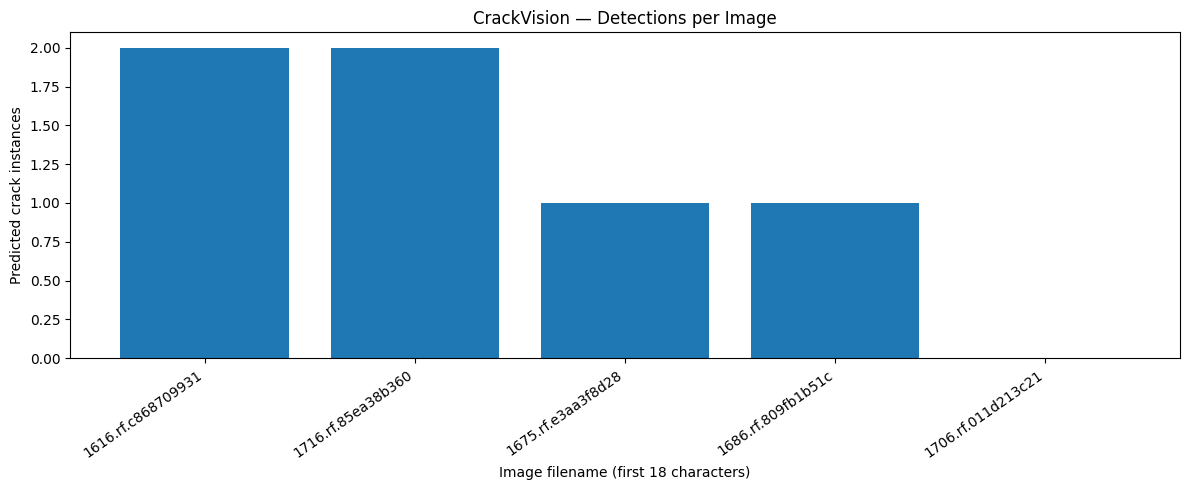

In [27]:
# Summarize the inspection run

# Summarize the batch inspection report
images_inspected = len(report_df)
images_with_detections = int(
    (report_df["detection_count"] > 0).sum()
)
images_without_detections = int(
    (report_df["detection_count"] == 0).sum()
)
total_detections = int(report_df["detection_count"].sum())

print("CRACKVISION — BATCH SUMMARY")
print("Images inspected:", images_inspected)
print("Images with detections:", images_with_detections)
print("Images without detections:", images_without_detections)
print("Total predicted instances:", total_detections)

if images_inspected:
    print(
        "Images with detections (%):",
        round(100 * images_with_detections / images_inspected, 2)
    )

# Visualize detection counts per image
plot_df = report_df.sort_values("detection_count", ascending=False)

plt.figure(figsize=(12, 5))
plt.bar(
    plot_df["image"].str.slice(0, 18),
    plot_df["detection_count"]
)
plt.xlabel("Image filename (first 18 characters)")
plt.ylabel("Predicted crack instances")
plt.title("CrackVision — Detections per Image")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [28]:
# Export the final batch report
INFERENCE_DIR = (
    Path("/content/drive/MyDrive/CrackVision")
    / "inference-results"
)
INFERENCE_DIR.mkdir(parents=True, exist_ok=True)

# Save a clean, complete image-level report
final_report = report_df.copy()

final_report["inspection_note"] = final_report["detection_count"].apply(
    lambda count: (
        "Review predicted crack regions"
        if count > 0
        else "No prediction at current threshold; manual review may be needed"
    )
)

csv_path = INFERENCE_DIR / "final_batch_report.csv"
json_path = INFERENCE_DIR / "final_batch_report.json"

final_report.to_csv(csv_path, index=False)
final_report.to_json(json_path, orient="records", indent=2)

summary = {
    "images_inspected": int(len(final_report)),
    "images_with_detections": int(
        (final_report["detection_count"] > 0).sum()
    ),
    "images_without_detections": int(
        (final_report["detection_count"] == 0).sum()
    ),
    "total_predicted_instances": int(
        final_report["detection_count"].sum()
    ),
    "confidence_threshold": 0.25,
    "image_size": 640,
}

summary_path = INFERENCE_DIR / "final_batch_summary.json"

with summary_path.open("w") as file:
    json.dump(summary, file, indent=2)

print("Final report exported successfully!")
print("CSV:", csv_path)
print("JSON:", json_path)
print("Summary:", summary_path)

display(final_report)

Final report exported successfully!
CSV: /content/drive/MyDrive/CrackVision/inference-results/final_batch_report.csv
JSON: /content/drive/MyDrive/CrackVision/inference-results/final_batch_report.json
Summary: /content/drive/MyDrive/CrackVision/inference-results/final_batch_summary.json


,image,status,detection_count,max_confidence,confidence_threshold,imgsz,inspection_note
0,1616.rf.c868709931a671796794fdbb95352c5a.jpg,crack_detected,2,0.479824,0.25,640,Review predicted crack regions
1,1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f.jpg,crack_detected,1,0.781898,0.25,640,Review predicted crack regions
2,1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8.jpg,crack_detected,1,0.645064,0.25,640,Review predicted crack regions
3,1706.rf.011d213c21ec78896c36728dcbc156f5.jpg,no_crack_detected,0,NaN,0.25,640,No prediction at current threshold; manual rev...
4,1716.rf.85ea38b36008beaa72c5d8541f734eb0.jpg,crack_detected,2,0.633069,0.25,640,Review predicted crack regions


In [30]:
# Final inference artifact audit
INFERENCE_DIR = (
    Path("/content/drive/MyDrive/CrackVision")
    / "inference-results"
)

required_files = [
    INFERENCE_DIR / "final_batch_report.csv",
    INFERENCE_DIR / "final_batch_report.json",
    INFERENCE_DIR / "final_batch_summary.json",
]

print("CRACKVISION — INFERENCE ARTIFACT AUDIT")

all_ok = True

for path in required_files:
    exists = path.is_file()
    print(f"{path.name}: {'PASS' if exists else 'MISSING'}")
    all_ok &= exists

if all_ok:
    # Read the saved files back from Drive
    saved_report = pd.read_csv(required_files[0])

    with required_files[1].open() as file:
        saved_json = json.load(file)

    with required_files[2].open() as file:
        saved_summary = json.load(file)

    print("\nReport rows:", len(saved_report))
    print("JSON records:", len(saved_json))
    print("Summary images inspected:", saved_summary["images_inspected"])

    consistent = (
        len(saved_report) == len(saved_json)
        == saved_summary["images_inspected"]
    )

    print("Record counts consistent:", consistent)
    all_ok &= consistent

print("Overall:", "PASS" if all_ok else "CHECK REQUIRED")

CRACKVISION — INFERENCE ARTIFACT AUDIT
final_batch_report.csv: PASS
final_batch_report.json: PASS
final_batch_summary.json: PASS

Report rows: 5
JSON records: 5
Summary images inspected: 5
Record counts consistent: True
Overall: PASS
